# Macro Forecast Combination

## Alcance y pregunta

¿La combinación estimada fuera de muestra mejora frente a seleccionar un pronóstico individual?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$\hat y=w\hat y_1+(1-w)\hat y_2$$

Se generan dos pronósticos insesgados con varianzas 1 y 2.25 y correlación variable. El peso que minimiza error cuadrático se estima sólo en 200 observaciones de entrenamiento y se restringe a [0,1]. Los RMSE se evalúan en 400 observaciones posteriores.

### Supuestos de identificación

Pronósticos disponibles en su fecha; distribución de errores estable entre entrenamiento y prueba; comparación pareada.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Se generan dos pronósticos insesgados con varianzas 1 y 2.25 y correlación variable. El peso que minimiza error cuadrático se estima sólo en 200 observaciones de entrenamiento y se restringe a [0,1]. Los RMSE se evalúan en 400 observaciones posteriores.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=600):
    y=rng.normal(size=n); z=rng.normal(size=(2,n)); e1=z[0]; e2=1.5*(level*z[0]+np.sqrt(1-level**2)*z[1])
    f1=y+e1;f2=y+e2; train=200
    d=e1[:train]-e2[:train]; w=np.clip(-np.dot(d,e2[:train])/np.dot(d,d),0,1)
    actual=y[train:]
    return {'Pronóstico 1 RMSE':np.sqrt(np.mean((f1[train:]-actual)**2)),
        'Media simple RMSE':np.sqrt(np.mean(((f1[train:]+f2[train:])/2-actual)**2)),
        'Combinación entrenada RMSE':np.sqrt(np.mean((w*f1[train:]+(1-w)*f2[train:]-actual)**2))},(np.arange(n-train),w*f1[train:]+(1-w)*f2[train:]-actual)


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[-0.6, -0.2, 0.2, 0.6, 0.9]
METRICS=['Pronóstico 1 RMSE', 'Media simple RMSE', 'Combinación entrenada RMSE']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.2 ; semilla: 20261018


,Métrica,Valor
0,Pronóstico 1 RMSE,1.005236
1,Media simple RMSE,0.993484
2,Combinación entrenada RMSE,0.922041


## Sensibilidad y variación entre réplicas

**Eje:** Correlación entre errores.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,-0.6,Pronóstico 1 RMSE,0.99567,0.98940,0.03176,0.93909,1.06095,40,0.00502
1,-0.6,Media simple RMSE,0.60470,0.60361,0.01707,0.57743,0.63915,40,0.00270
2,-0.6,Combinación entrenada RMSE,0.53526,0.53138,0.01634,0.50819,0.56196,40,0.00258
3,-0.2,Pronóstico 1 RMSE,0.99567,0.98940,0.03176,0.93909,1.06095,40,0.00502
4,-0.2,Media simple RMSE,0.81505,0.81352,0.02371,0.77522,0.84748,40,0.00375
5,-0.2,Combinación entrenada RMSE,0.74900,0.74566,0.02549,0.71036,0.79563,40,0.00403
6,0.2,Pronóstico 1 RMSE,0.99567,0.98940,0.03176,0.93909,1.06095,40,0.00502
7,0.2,Media simple RMSE,0.97958,0.97546,0.03201,0.92903,1.03684,40,0.00506
8,0.2,Combinación entrenada RMSE,0.90144,0.90493,0.03316,0.85480,0.95643,40,0.00524
9,0.6,Pronóstico 1 RMSE,0.99567,0.98940,0.03176,0.93909,1.06095,40,0.00502


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

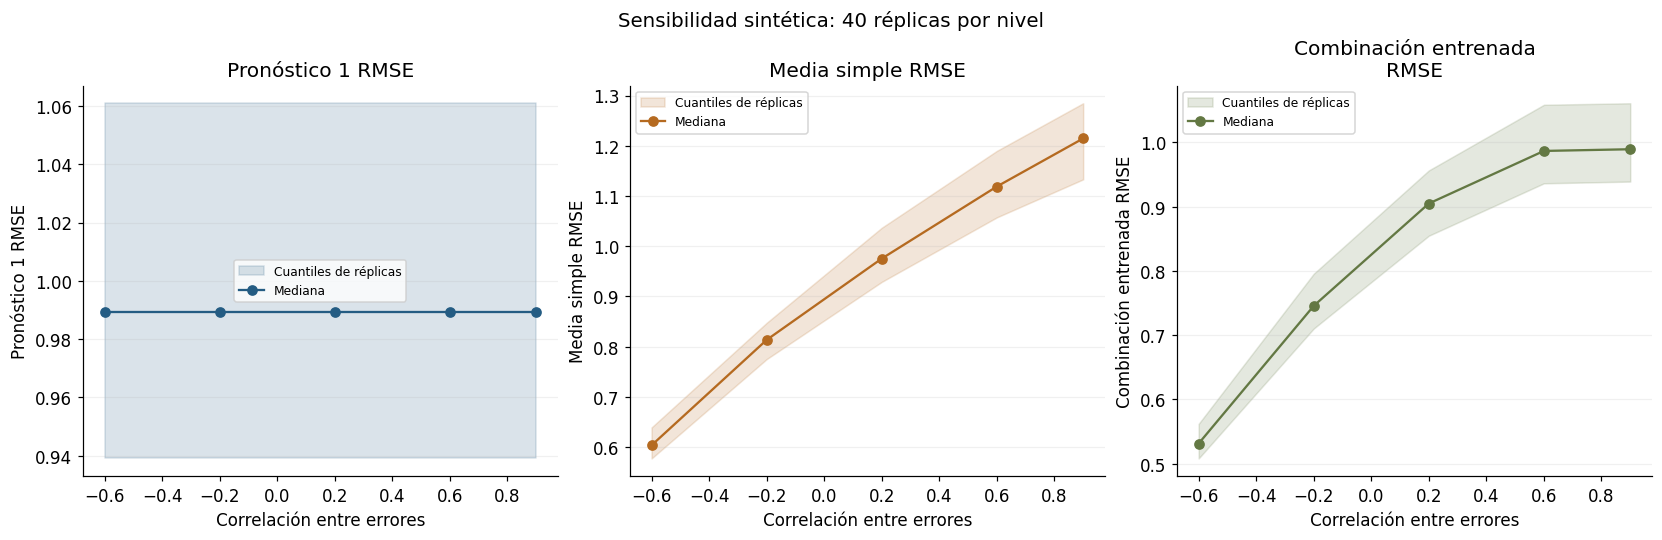

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Correlación entre errores',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Pronóstico 1 RMSE: mediana 0.989399 en nivel -0.6; 0.989399 en nivel 0.9.
  Último escenario: cuantiles [0.939092, 1.06095], media 0.995673, error MC de la media 0.00502.
Media simple RMSE: mediana 0.603614 en nivel -0.6; 1.21472 en nivel 0.9.
  Último escenario: cuantiles [1.13323, 1.2848], media 1.21364, error MC de la media 0.00653.
Combinación entrenada RMSE: mediana 0.531384 en nivel -0.6; 0.989399 en nivel 0.9.
  Último escenario: cuantiles [0.939092, 1.06095], media 0.995673, error MC de la media 0.00502.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

Sin quiebres de régimen ni revisiones. Los pesos óptimos de población pueden ser negativos; aquí se impone una combinación convexa explícita.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.